## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Mahati Vedula

**Date:** 10/12/2026

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

**Q1**

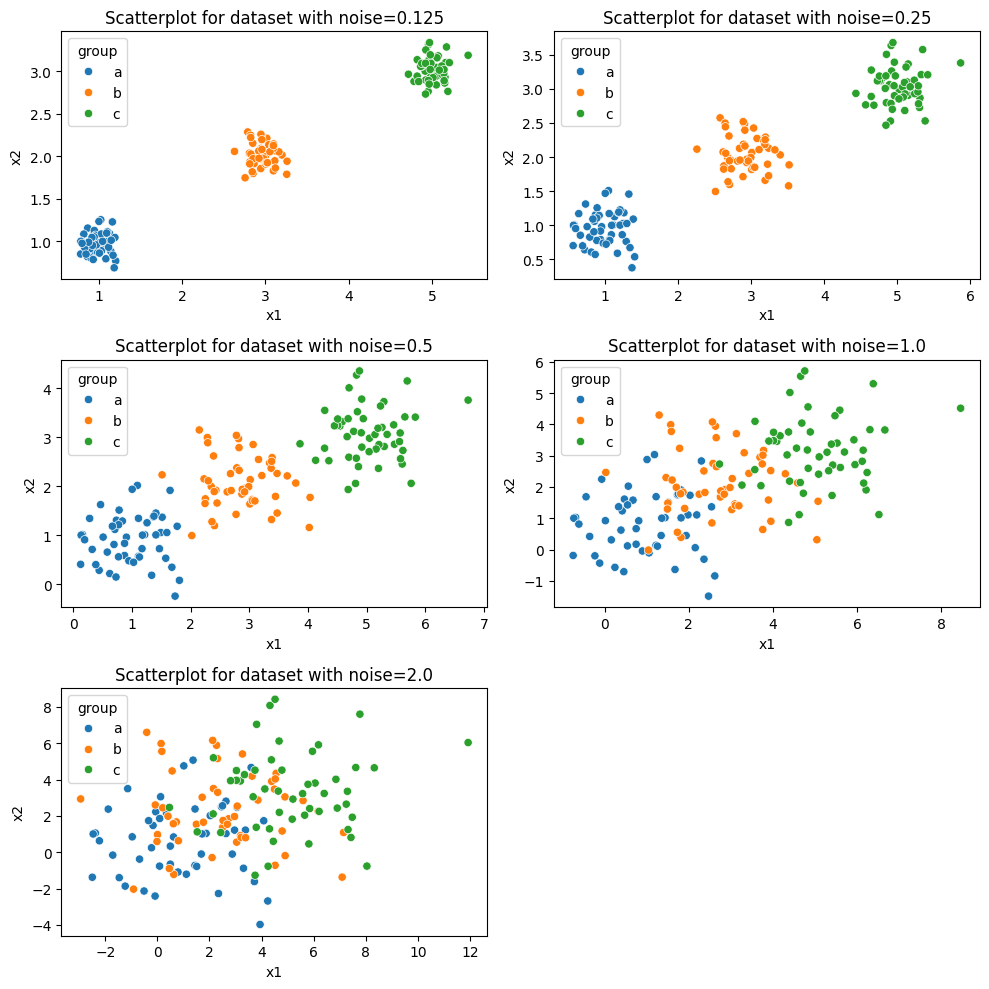

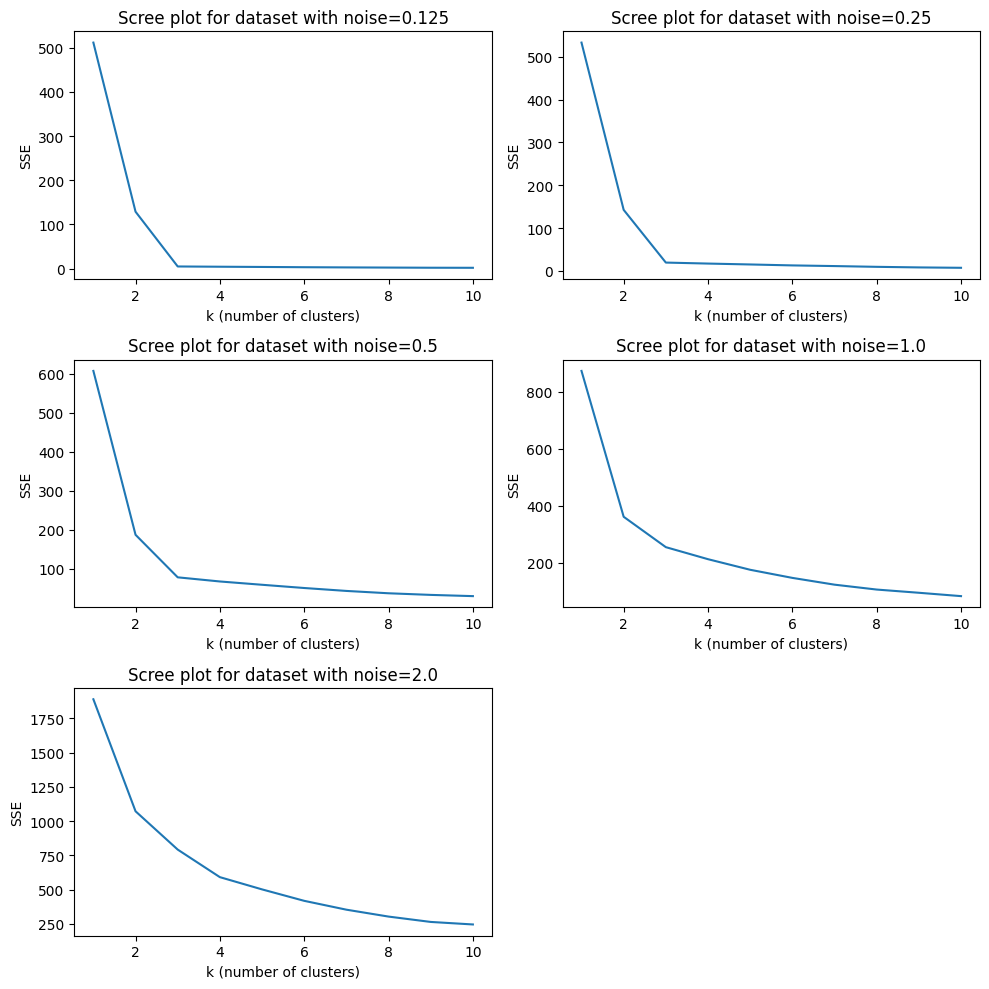

In [66]:
# Part 1: Run the code to create the 4 datasets

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# Part 2: Make scatterplots of the $(X1,X2)$ points by group for each of the datasets

# print(df0_125.head(n=10).to_string(), '\n')
fig,axes = plt.subplots(3,2,figsize=(10,10))
sns.scatterplot(data=df0_125,x='x1',y='x2',hue='group',ax=axes[0,0]).set(title="Scatterplot for dataset with noise=0.125", xlabel="x1", ylabel="x2")
sns.scatterplot(data=df0_25,x='x1',y='x2',hue='group',ax=axes[0,1]).set(title="Scatterplot for dataset with noise=0.25", xlabel="x1", ylabel="x2")
sns.scatterplot(data=df0_5,x='x1',y='x2',hue='group',ax=axes[1,0]).set(title="Scatterplot for dataset with noise=0.5", xlabel="x1", ylabel="x2")
sns.scatterplot(data=df1_0,x='x1',y='x2',hue='group',ax=axes[1,1]).set(title="Scatterplot for dataset with noise=1.0", xlabel="x1", ylabel="x2")
sns.scatterplot(data=df2_0,x='x1',y='x2',hue='group',ax=axes[2,0]).set(title="Scatterplot for dataset with noise=2.0", xlabel="x1", ylabel="x2")
axes[2, 1].set_axis_off()
plt.tight_layout()
plt.show()


# Create a scree plot for each of the datasets; pay attention to the vertical axis across plots
from sklearn.cluster import KMeans

fig,axes = plt.subplots(3,2,figsize=(10,10))

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0, 0]).set(title="Scree plot for dataset with noise=0.125", xlabel="k (number of clusters)", ylabel="SSE")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0, 1]).set(title="Scree plot for dataset with noise=0.25", xlabel="k (number of clusters)", ylabel="SSE")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[1, 0]).set(title="Scree plot for dataset with noise=0.5", xlabel="k (number of clusters)", ylabel="SSE")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[1, 1]).set(title="Scree plot for dataset with noise=1.0", xlabel="k (number of clusters)", ylabel="SSE")
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[2, 0]).set(title="Scree plot for dataset with noise=2.0", xlabel="k (number of clusters)", ylabel="SSE")
axes[2, 1].set_axis_off()
plt.tight_layout()
plt.show()


1. Code run (see above)

2. Scatterplots created (see above). As the noise increases, the clusters start to merge together. When the noise was lower (up through 0.5) the clusters remained distinct and the groups did not overlap. With noise 1.0 and 2.0, the clusters actually started overlapping to create "sprinkles." 

3. Scree plot created (see above). The elbow is more distinct and sharper with lower noise levels, while the line is more curved and continuous. The sharp changes make it easier to pick the best k because there is a point where an additional cluster does not dramatically reduce SSE. However, as the like is more curved, the rate of change of SSE is lower, meaning it is harder to find the sharp change. Additionally, the datasets with higher noise also have higher SSEs, even when the number of clusters are very large. For example with 10 clusters, the SSE is close to 0 when noise is 0.125 and over 250 when the noise is 2.0. 

4. The elbow is the bend created in the scree plot where additional clusters result in diminishing classification benefits, or lower reductions in SSE. Beyond the elbow, additional clusters do not improve the K-means algorithm much and run the risk of overfitting data. The elbow helps select the k with the best sweet spot, where the algorithm is not too general nor too specific to the training dataset. With noise levels 0.125, 0.25, and 0.5, there is diminishing value in SSE improvement beyond 3 clusters (clear elbow at k=3). However, with noise levels 1.0 and 2.0, the elbow is harder to spot becuase the curve is more continuous, and a k of 4 or 5 still make rational sense.

**Q2**

In [68]:
# Part 1: Load the CSV file, filter rows to select only year 2020, drop rows with missing values, and clean further
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
# df.head(n=20)
df = df[df['Year'] == 2020]
df = df.dropna()
df.head(n=20)

# test for further cleaning
print(df.head(n=15).to_string(), '\n')
print(df.shape, '\n')
print(df.dtypes, '\n')
print(df.describe().to_string(), '\n')



     index  Year      Country  Spending (2020 USD)  Percent of GDP  Percent of Government Spending  Spending per Capita
32      32  2020  Afghanistan           279.576955        0.013589                        0.049728             7.181899
66      66  2020      Albania           187.433234        0.012583                        0.037952            65.126211
100    100  2020      Algeria          9708.277440        0.066600                        0.173924           221.392384
134    134  2020       Angola           993.594405        0.014442                        0.074624            30.231680
168    168  2020    Argentina          2830.929705        0.007269                        0.017268            62.636731
202    202  2020      Armenia           633.960400        0.049827                        0.162572           213.958961
236    236  2020    Australia         27300.894701        0.020118                        0.044978          1070.623322
270    270  2020      Austria          3

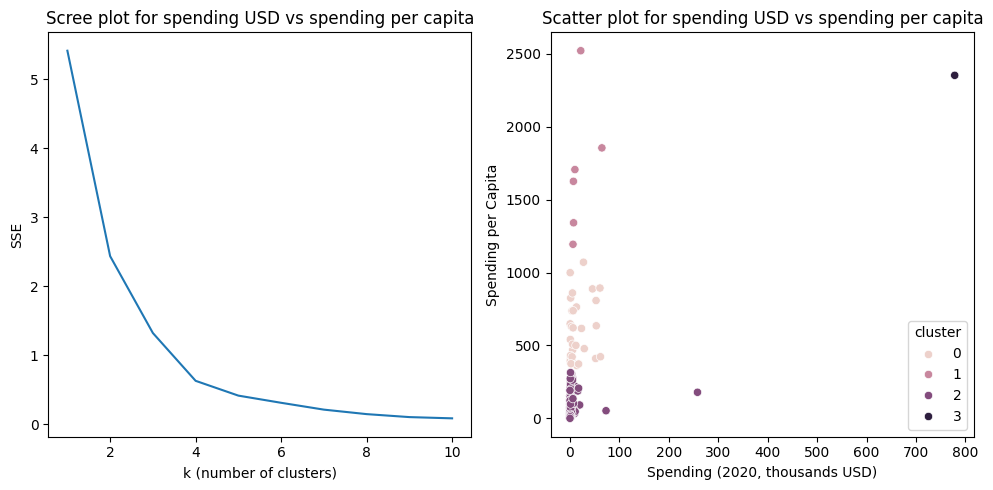

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
1          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   
2        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
3          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... spending_per_capita_scaled            \
            max  count    mean  ...                        75%       max   
cluster                         ...                                        
0        5506.0   30.0  2020.0  ...                   0.757329  1.070623   
1        4656.0    6.0  2020.0  ...                   1.817220  2.520399   
2        5880.0  111.0  2020.0  ...                   0.125388  0.314201   
3        5540.0    1.0  2020.0  ...                   2.351632  2.351632   

        spending_scaled                                                 \
                  count        mean        std         min         25%   
cluster                                                                  
0                  30.0   17.077591  20.583053    0.405790    2.294040   
1                   6.0   19.443362  22.861507    6.095709    7.023252   
2                 111.0    4.859185  25.405739    0.008622    0.130010   
3                   1.0  778.397200        NaN  778.397200  778.397200   

                                             
                50%         75%         max  
cluster                                      
0          5.857061   26.296001   61.712537  
1          8.624226   18.857070   64.558400  
2          0.382465    2.297032  257.973430  
3        778.397200  778.397200  778.397200  

[4 rows x 72 columns]

In [ ]:
# Part 2: Spending (2020 USD) vs Spending per Capita

# Max-min normalize `Spending (2020 USD)` and `Spending per Capita`
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min','max'])

fig,axes = plt.subplots(1,2,figsize=(10,5))

# Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0]).set(title="Scree plot for spending USD vs spending per capita", xlabel="k (number of clusters)", ylabel="SSE")

# Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership
model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0)
model.fit(X)
df['cluster'] = model.labels_
df['spending_scaled'] = df['Spending (2020 USD)']/1000
sns.scatterplot(data=df, x='spending_scaled', y='Spending per Capita', ax=axes[1], hue='cluster').set(title="Scatterplot for spending USD vs spending per capita", xlabel="Spending (2020, thousands USD)", ylabel="Spending per Capita")

plt.tight_layout()
plt.show()

# Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`)
df.groupby('cluster').describe()

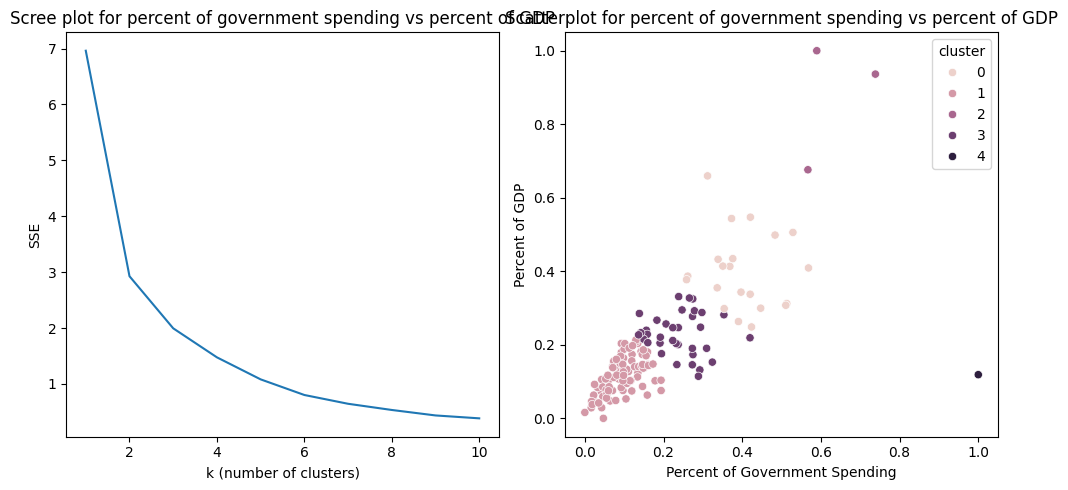

Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 21.0  0.401576  0.084335  0.258544   
1                                 88.0  0.095471  0.044456  0.000000   
2                                  3.0  0.631647  0.093179  0.566960   
3                                 35.0  0.239287  0.065736  0.136627   
4                                  1.0  1.000000       NaN  1.000000   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.350780  0.390448  0.446940  0.568430           21.0  0.399439   
1        0.061369  0.095493  0.129838  0.193838           88.0  0.117075   
2        0.578246  0.589532  0.663990  0.738448            3.0  0.870855   
3        0.191451  0.237608  0.276672  0.419785           35.0  0.228554   
4        1.000000  1.000000  1.000000  1.000000            1.0  0.118758   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.105184  0.248563  0.312245  0.386770  0.434443  0.659511  
1        0.049950  0.000000  0.076837  0.116962  0.148289  0.213052  
2        0.171577  0.676168  0.806282  0.936397  0.968198  1.000000  
3        0.056117  0.114445  0.195524  0.227137  0.272167  0.331220  
4             NaN  0.118758  0.118758  0.118758  0.118758  0.118758

In [100]:
# Part 3: Percent of govt spending vs percent of GDP

# Max-min normalize `Percent of Govt Spending` and `Percent of GDP`
features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min','max'])

fig,axes = plt.subplots(1,2,figsize=(10,5))

# Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0]).set(title="Scree plot for percent of government spending vs percent of GDP", xlabel="k (number of clusters)", ylabel="SSE")

# Make a scatter plot of `Percent of Govt Spending` and `Percent of GDP`, and hue the dots by their cluster membership
model = KMeans(n_clusters=5, max_iter=300, n_init=10, random_state=0)
model.fit(X)
X['cluster'] = model.labels_
sns.scatterplot(data=X, x='Percent of Government Spending', y='Percent of GDP', ax=axes[1], hue='cluster').set(title="Scatterplot for percent of government spending vs percent of GDP", xlabel="Percent of Government Spending", ylabel="Percent of GDP")

plt.tight_layout()
plt.show()

# Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`)
X.groupby('cluster').describe()

Spending (2020 USD)                                                   \
                      count      mean       std      min       25%       50%   
cluster                                                                        
0                      86.0  0.005787  0.035768  0.00000  0.000093  0.000359   
1                       1.0  1.000000       NaN  1.00000  1.000000  1.000000   
2                      30.0  0.011646  0.023298  0.00020  0.000660  0.002126   
3                      26.0  0.019684  0.024311  0.00051  0.004070  0.007514   
4                       5.0  0.028096  0.031700  0.00782  0.008906  0.012808   

                            Spending per Capita            ...  \
              75%       max               count      mean  ...   
cluster                                                    ...   
0        0.001452  0.331409                86.0  0.027665  ...   
1        1.000000  1.000000                 1.0  0.933024  ...   
2        0.011097  0.093692                30.0  0.085459  ...   
3        0.028020  0.077938                26.0  0.242913  ...   
4        0.028017  0.082927                 5.0  0.706112  ...   

        Percent of Government Spending           Percent of GDP            \
                                   75%       max          count      mean   
cluster                                                                     
0                             0.161369  0.324036           86.0  0.126272   
1                             0.258544  0.258544            1.0  0.377222   
2                             0.441105  1.000000           30.0  0.345988   
3                             0.133325  0.158699           26.0  0.167970   
4                             0.589532  0.738448            5.0  0.687596   

                                                                     
              std       min       25%       50%       75%       max  
cluster                                                              
0        0.058926  0.000000  0.078813  0.126787  0.169980  0.267089  
1             NaN  0.377222  0.377222  0.377222  0.377222  0.377222  
2        0.112944  0.118758  0.283279  0.326101  0.412364  0.676168  
3        0.056139  0.063195  0.138540  0.155160  0.207045  0.285294  
4        0.288287  0.298475  0.543595  0.659511  0.936397  1.000000  

[5 rows x 32 columns]

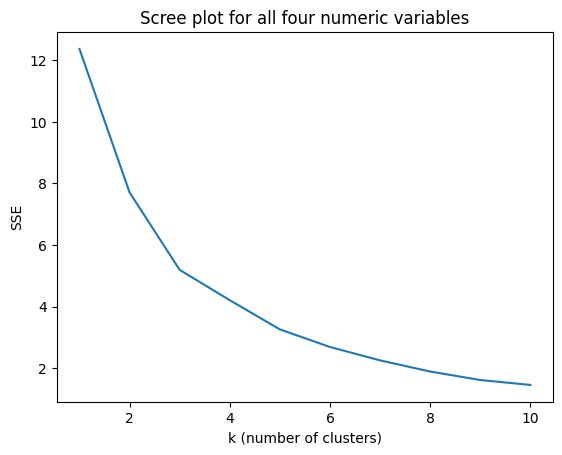

In [ ]:
# Part 4: Use k means clustering with all four numeric variables: 
# `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`.

# Scaling
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

# Scree plot
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
X['cluster'] = model.labels_
sns.lineplot(x=ks, y=SSE).set(title="Scree plot for all four numeric variables", xlabel="k (number of clusters)", ylabel="SSE")
X.groupby('cluster').describe()

1. Dataset loaded, filtered, and dropped (see above). There is no additional data cleaning needed because all variables are of the right type, and I also ended up with 148 countries. All countries have unique names, and all numbers are presented as numerical values (no strings). The percentages are also between 0.0 and 1.0.
2. Data scaled, scree plot and scatterplot created (see above). After grouping based on cluster and creating a describe table, while cross-checking the USA datapoint from the CSV file, I noticed that the United States is an outlier point on the scatterplot because it has unusually high spending and spending per capita. Because it is so far from the other data points, it actually ends up being its own cluster. I noticed that relative spending tends to be low across clusters but spending per capita varies a lot (since each country has a unique population) so the scatterplot looks like a vertical line, and clusters are formed based on where a country falls in that vertical. The United States is the exception to this pattern, with both high overall and per capita spend. In the describe table, we can see that the mean overall spending for cluster 3 (USA) is abnormally higher than cluster 1, 2, and 3, which are incrementallty greater than one another.
3. Data scaled, scree plot and scatterplot created (see above). The resulting scatterplot for this comparison is fairly linear, where an increased percent of government spending correlates with an increased percent of GDP. This makes sense, as GDP is a country's economic productivity, and taxes are collected to fund government spending; a higher GDP means larger government budgets. In this situation, 5 clusters made the most sense, and clusters are groups along the diagonal of the scatterplot. There is yet another outlier with 100% of it's government spending being used, and is its own cluster. The describe table shows this same pattern, with clusters 0-3 increasing in percent of GDP and percent of government spending (not necessarily in order from 0-3) and cluster 4 being off on its own with high percent of government spend but a low percent (~11%) of GDP.

4. K means clustering done (see above). With all four features used in cluster prediction, the scree plot gives us a less definitive k and the elbow is not very intuitive. However, the number of clusters seems to fall around 5 clusters. The results are similar, since the previous univariate k-means also gave us 4-5 clusters. However, SSE is a bit higher (~2 after 10 iterations whereas it is below 1 in previous steps). There is also still one cluster, cluster 1, which consists of only one data point, signaling an outlier.

5. The k-means algorithms found some patterns in the spending through clustering, but only some are meaningful discoveries. For example, since most data points in part 2 were low in total spend and varied in spend per capita, clustering the data helped identify groups of countries with similar spending habits. However, the relationship in part 3 is already linear, signaling a correlation between percent of government spend and percent of GDP. Since the data is linear, it makes more sense to define a regression-like pattern rather than a group of distinct clusters. Clustering is a useful technique when data is non-linear and more random, yet distinct groups of points emerge.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 7332ca784692af104cb3da7d72f02cf533d59258
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Here is my file, and here is the rubric. What do I need to improve, and is there anything I missed? *attached notebook and scoring rubric*
2. Give the changes to me in a list format

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. (2c) Make the scatterplot explanation specific.
2. (2a/3a) Show the normalization check.
3. (3c/3e) Correct Part 3 values and explanation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | My wording was indeed vague and can be improved |
| 2 | Accept | Helps illustrate that scaling was done correctly |
| 3 | Accept | I misread the value and need to correct the numbers in my explaantion |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

1. Code run (see above)

2. Scatterplots created (see above). As the noise increases, the clusters start to merge together. When the noise was lower (up through 0.5) the clusters remained distinct and the groups did not overlap. At noise 1.0, neighboring groups (a/b and b/c) start to overlap. At 2.0, all three are heavily mixed.

3. Scree plot created (see above). The elbow is more distinct and sharper with lower noise levels, while the line is more curved and continuous. The sharp changes make it easier to pick the best k because there is a point where an additional cluster does not dramatically reduce SSE. However, as the like is more curved, the rate of change of SSE is lower, meaning it is harder to find the sharp change. Additionally, the datasets with higher noise also have higher SSEs, even when the number of clusters are very large. For example with 10 clusters, the SSE is close to 0 when noise is 0.125 and over 250 when the noise is 2.0. 

4. The elbow is the bend created in the scree plot where additional clusters result in diminishing classification benefits, or lower reductions in SSE. Beyond the elbow, additional clusters do not improve the K-means algorithm much and run the risk of overfitting data. The elbow helps select the k with the best sweet spot, where the algorithm is not too general nor too specific to the training dataset. With noise levels 0.125, 0.25, and 0.5, there is diminishing value in SSE improvement beyond 3 clusters (clear elbow at k=3). However, with noise levels 1.0 and 2.0, the elbow is harder to spot becuase the curve is more continuous, and a k of 4 or 5 still make rational sense.

In [ ]:
# Your Phase 2 solution to the problem goes here.

# Part 2: Spending (2020 USD) vs Spending per Capita

# Max-min normalize `Spending (2020 USD)` and `Spending per Capita`
features = ['Spending (2020 USD)', 'Spending per Capita']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min','max'])

fig,axes = plt.subplots(1,2,figsize=(10,5))

# Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0]).set(title="Scree plot for spending USD vs spending per capita", xlabel="k (number of clusters)", ylabel="SSE")

# Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership
model = KMeans(n_clusters=4, max_iter=300, n_init=10, random_state=0)
model.fit(X)
df['cluster'] = model.labels_
df['spending_scaled'] = df['Spending (2020 USD)']/1000
sns.scatterplot(data=df, x='spending_scaled', y='Spending per Capita', ax=axes[1], hue='cluster').set(title="Scatterplot for spending USD vs spending per capita", xlabel="Spending (2020, thousands USD)", ylabel="Spending per Capita")

plt.tight_layout()
plt.show()

# Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`)
df.groupby('cluster').describe()


In [ ]:
# Part 3: Percent of govt spending vs percent of GDP

# Max-min normalize `Percent of Govt Spending` and `Percent of GDP`
features = ['Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min','max'])

fig,axes = plt.subplots(1,2,figsize=(10,5))

# Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE, ax=axes[0]).set(title="Scree plot for percent of government spending vs percent of GDP", xlabel="k (number of clusters)", ylabel="SSE")

# Make a scatter plot of `Percent of Govt Spending` and `Percent of GDP`, and hue the dots by their cluster membership
model = KMeans(n_clusters=5, max_iter=300, n_init=10, random_state=0)
model.fit(X)
X['cluster'] = model.labels_
sns.scatterplot(data=X, x='Percent of Government Spending', y='Percent of GDP', ax=axes[1], hue='cluster').set(title="Scatterplot for percent of government spending vs percent of GDP", xlabel="Percent of Government Spending", ylabel="Percent of GDP")

plt.tight_layout()
plt.show()

# Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`)
X.groupby('cluster').describe()

In [ ]:
# Part 4: Use k means clustering with all four numeric variables: 
# `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`.

# Scaling
features = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(['min','max'])

# Scree plot
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
X['cluster'] = model.labels_
sns.lineplot(x=ks, y=SSE).set(title="Scree plot for all four numeric variables", xlabel="k (number of clusters)", ylabel="SSE")
X.groupby('cluster').describe()

1. Dataset loaded, filtered, and dropped (see above). There is no additional data cleaning needed because all variables are of the right type, and I also ended up with 148 countries. All countries have unique names, and all numbers are presented as numerical values (no strings). The percentages are also between 0.0 and 1.0.
2. Data scaled, scree plot and scatterplot created (see above). After grouping based on cluster and creating a describe table, while cross-checking the USA datapoint from the CSV file, I noticed that the United States is an outlier point on the scatterplot because it has unusually high spending and spending per capita. Because it is so far from the other data points, it actually ends up being its own cluster. I noticed that relative spending tends to be low across clusters but spending per capita varies a lot (since each country has a unique population) so the scatterplot looks like a vertical line, and clusters are formed based on where a country falls in that vertical. The United States is the exception to this pattern, with both high overall and per capita spend. In the describe table, we can see that the mean overall spending for cluster 3 (USA) is abnormally higher than cluster 1, 2, and 3, which are incrementallty greater than one another.
3. Data scaled, scree plot and scatterplot created (see above). The resulting scatterplot for this comparison is fairly linear, where an increased percent of government spending correlates with an increased percent of GDP. This makes sense, as GDP is a country's economic productivity, and taxes are collected to fund government spending; a higher GDP means larger government budgets. In this situation, 5 clusters made the most sense, and clusters are groups along the diagonal of the scatterplot. There is yet another outlier with 1% of it's government spending being used, and is its own cluster. The describe table shows this same pattern, with clusters 0-3 increasing in percent of GDP and percent of government spending (not necessarily in order from 0-3) and cluster 4 being off on its own with high percent of government spend but a low percent (~11%) of GDP.

4. K means clustering done (see above). With all four features used in cluster prediction, the scree plot gives us a less definitive k and the elbow is not very intuitive. However, the number of clusters seems to fall around 5 clusters. The results are similar, since the previous univariate k-means also gave us 4-5 clusters. However, SSE is a bit higher (~2 after 10 iterations whereas it is below 1 in previous steps). There is also still one cluster, cluster 1, which consists of only one data point, signaling an outlier.

5. The k-means algorithms found some patterns in the spending through clustering, but only some are meaningful discoveries. For example, since most data points in part 2 were low in total spend and varied in spend per capita, clustering the data helped identify groups of countries with similar spending habits. However, the relationship in part 3 is already linear, signaling a correlation between percent of government spend and percent of GDP. Since the data is linear, it makes more sense to define a regression-like pattern rather than a group of distinct clusters. Clustering is a useful technique when data is non-linear and more random, yet distinct groups of points emerge.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements the AI made was in my quality of explanation (understandability) and sanity checks in code, such as verifying min and max after scaling. The AI did not make mistakes since I gave it the context of my project and the rubric I was being scored with, so the suggestions were relevant. One limitation of the AI is that it is picky and often suggestions nice, but not neccessary, changes. It is up to me to decide if the change improves my project or not. I verified the soltion by manually cross-checking the rubric and using my own human judgement to decide if the change was impactful, relevant and necessary. I do not have remaining concerns for this reason.